In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/Bhumika Chandan/Downloads/Dataset .csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
print("Missing Longitude:", df["Longitude"].isnull().sum())

print("Missing Latitude:", df["Latitude"].isnull().sum())

Missing Longitude: 0
Missing Latitude: 0


In [4]:
display(df[["Restaurant Name", "City", "Longitude", "Latitude"]].head(10))

,Restaurant Name,City,Longitude,Latitude
0,Le Petit Souffle,Makati City,121.027535,14.565443
1,Izakaya Kikufuji,Makati City,121.014101,14.553708
2,Heat - Edsa Shangri-La,Mandaluyong City,121.056831,14.581404
3,Ooma,Mandaluyong City,121.056475,14.585318
4,Sambo Kojin,Mandaluyong City,121.057508,14.584450
5,Din Tai Fung,Mandaluyong City,121.056314,14.583764
6,Buffet 101,Pasay City,120.979667,14.531333
7,Vikings,Pasay City,120.979333,14.540000
8,Spiral - Sofitel Philippine Plaza Manila,Pasay City,120.980090,14.552990
9,Locavore,Pasig City,121.056532,14.572041


In [5]:
geo_df = df.dropna(
    subset=["Longitude", "Latitude"]
).copy()

geo_df = geo_df[
    (geo_df["Longitude"].between(-180, 180)) &
    (geo_df["Latitude"].between(-90, 90))
]

print("Original Records:", len(df))
print("Valid Geographical Records:", len(geo_df))

Original Records: 9551
Valid Geographical Records: 9551


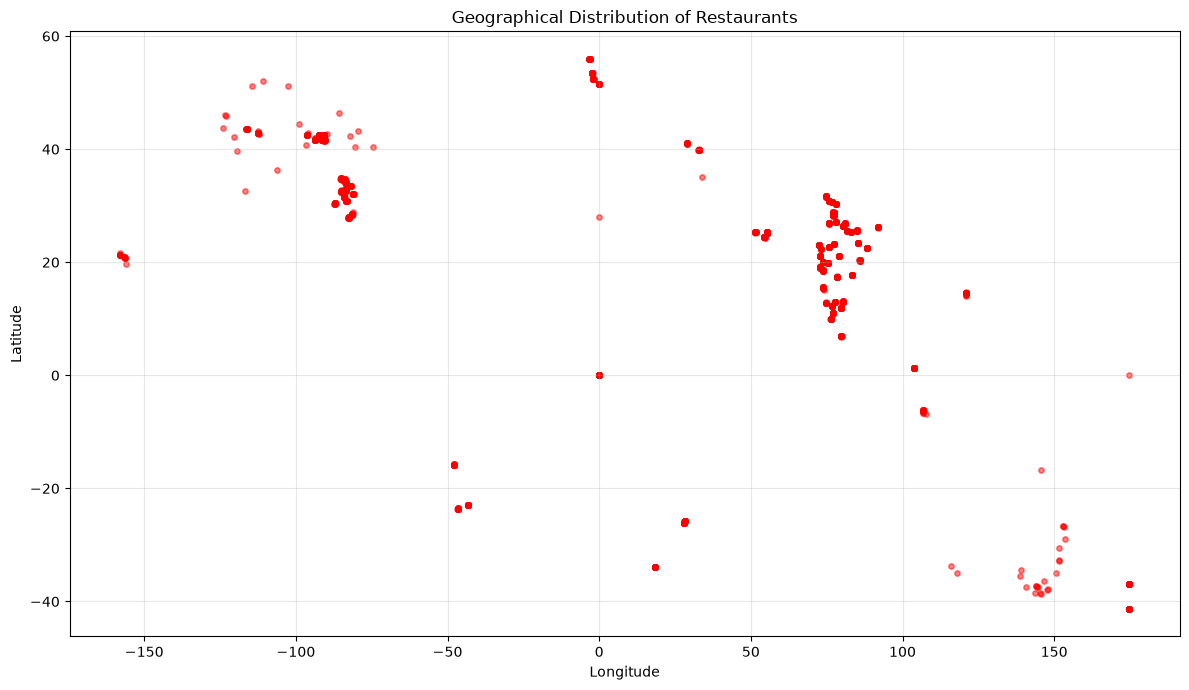

In [12]:
plt.figure(figsize=(12, 7))

plt.scatter(
    geo_df["Longitude"],
    geo_df["Latitude"],
    color="red",
    alpha=0.5,
    s=15
)

plt.title("Geographical Distribution of Restaurants")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Restaurant_Geographic_Distribution.png", dpi=300)

plt.show()

In [7]:
city_counts = (
    geo_df.groupby("City")["Restaurant ID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Cities with Most Restaurants:")

display(city_counts.head(10))

Top 10 Cities with Most Restaurants:


City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Guwahati          21
Ahmedabad         21
Amritsar          21
Name: Restaurant ID, dtype: int64

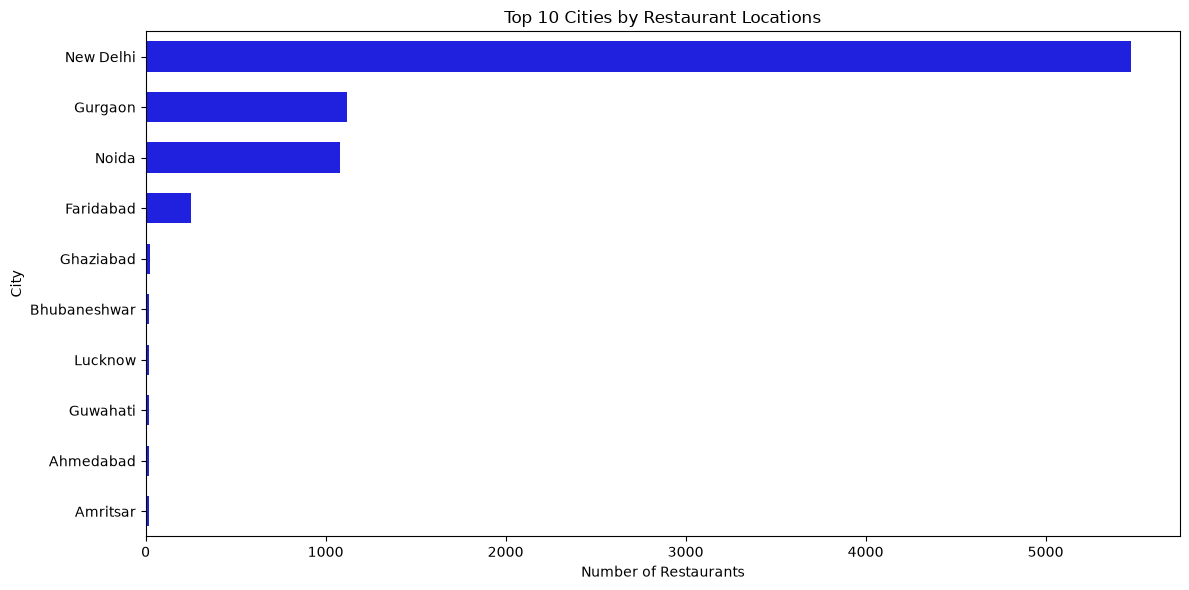

In [11]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=city_counts.head(10).values,
    y=city_counts.head(10).index,
    color="blue",
    width=0.6
)

plt.title("Top 10 Cities by Restaurant Locations")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")

plt.tight_layout()
plt.savefig("Restaurant_City_Clusters.png", dpi=300)

plt.show()

In [9]:
city_counts.to_csv("Restaurant_Geographic_City_Analysis.csv")

geo_df[
    ["Restaurant ID", "Restaurant Name", "City", "Longitude", "Latitude"]
].to_csv("Restaurant_Geographic_Coordinates.csv", index=False)

print("Geographic Analysis Task Completed Successfully!")

Geographic Analysis Task Completed Successfully!
